In [1]:
import numpy as np
import matplotlib.pyplot as plt
from abc import ABC, abstractmethod


class SpatialStrategy(ABC):

    @abstractmethod
    def resolve(self, **kwargs):
        pass


class NDVIStrategy(SpatialStrategy):

    def resolve(
        self,
        nir,
        red
    ):

        nir = np.asarray(
            nir,
            dtype=float
        )

        red = np.asarray(
            red,
            dtype=float
        )

        nir, red = np.broadcast_arrays(
            nir,
            red
        )

        denominator = nir + red

        if np.any(
            denominator == 0
        ):

            raise ValueError(
                "NIR + RED no puede ser cero"
            )

        return (
            (nir - red)
            / denominator
        )


class KrigingStrategy(SpatialStrategy):

    def __init__(
        self,
        kind="ordinary"
    ):

        self.kind = kind.lower()


    def distance(
        self,
        a,
        b
    ):

        return np.sqrt(
            (
                (
                    a[:, None, :]
                    - b[None, :, :]
                ) ** 2
            ).sum(axis=2)
        )


    def semivariogram(
        self,
        distance,
        sill=1,
        range_=1,
        nugget=0
    ):

        return (
            nugget
            + sill
            * (
                1
                - np.exp(
                    -distance
                    / range_
                )
            )
        )


    def resolve(
        self,
        points,
        values,
        targets=None,
        grid=None
    ):

        points = np.asarray(
            points,
            dtype=float
        )

        values = np.asarray(
            values,
            dtype=float
        )

        if targets is None:

            x = np.asarray(
                grid[0]
            )

            y = np.asarray(
                grid[1]
            )

            X, Y = np.meshgrid(
                x,
                y
            )

            targets = np.column_stack(
                [
                    X.ravel(),
                    Y.ravel()
                ]
            )

            shape = X.shape

        else:

            targets = np.asarray(
                targets,
                dtype=float
            )

            shape = None

        n = len(points)

        D = self.distance(
            points,
            points
        )

        sill = (
            np.var(values)
            if np.var(values) > 0
            else 1
        )

        G = self.semivariogram(
            D,
            sill=sill
        )

        np.fill_diagonal(
            G,
            0
        )

        predictions = []
        variances = []

        if self.kind == "ordinary":

            A = np.zeros(
                (n + 1, n + 1)
            )

            A[:n, :n] = G
            A[:n, -1] = 1
            A[-1, :n] = 1

            for target in targets:

                d = np.linalg.norm(
                    points - target,
                    axis=1
                )

                g = self.semivariogram(
                    d,
                    sill=sill
                )

                b = np.r_[
                    g,
                    1
                ]

                solution = np.linalg.solve(
                    A + np.eye(n + 1) * 1e-10,
                    b
                )

                weights = solution[:n]

                predictions.append(
                    np.dot(
                        weights,
                        values
                    )
                )

                variances.append(
                    np.dot(
                        weights,
                        g
                    )
                    + solution[-1]
                )

        elif self.kind == "universal":

            F = np.column_stack(
                [
                    np.ones(n),
                    points[:, 0],
                    points[:, 1]
                ]
            )

            for target in targets:

                f0 = np.array(
                    [
                        1,
                        target[0],
                        target[1]
                    ]
                )

                d = np.linalg.norm(
                    points - target,
                    axis=1
                )

                g = self.semivariogram(
                    d,
                    sill=sill
                )

                A = np.block(
                    [
                        [
                            G,
                            F
                        ],
                        [
                            F.T,
                            np.zeros((3, 3))
                        ]
                    ]
                )

                b = np.r_[
                    g,
                    f0
                ]

                solution = np.linalg.solve(
                    A + np.eye(n + 3) * 1e-10,
                    b
                )

                weights = solution[:n]

                predictions.append(
                    np.dot(
                        weights,
                        values
                    )
                )

                variances.append(
                    np.dot(
                        weights,
                        g
                    )
                )

        else:

            raise ValueError(
                "kind debe ser ordinary o universal"
            )

        predictions = np.asarray(
            predictions
        )

        variances = np.asarray(
            variances
        )

        if shape is not None:

            predictions = predictions.reshape(
                shape
            )

            variances = variances.reshape(
                shape
            )

        return {
            "prediction": predictions,
            "variance": variances
        }


    def cross_validate(
        self,
        points,
        values
    ):

        points = np.asarray(
            points,
            dtype=float
        )

        values = np.asarray(
            values,
            dtype=float
        )

        predicted = []

        for i in range(
            len(values)
        ):

            mask = np.ones(
                len(values),
                dtype=bool
            )

            mask[i] = False

            result = self.resolve(
                points=points[mask],
                values=values[mask],
                targets=[points[i]]
            )

            predicted.append(
                result["prediction"][0]
            )

        predicted = np.asarray(
            predicted
        )

        error = (
            values
            - predicted
        )

        return {
            "observed": values,
            "predicted": predicted,
            "error": error,
            "MAE": np.mean(
                np.abs(error)
            ),
            "RMSE": np.sqrt(
                np.mean(error ** 2)
            )
        }


class SpatialFacade:

    def __init__(
        self,
        mode="ndvi",
        kind="ordinary"
    ):

        self.mode = mode.lower()

        if self.mode == "ndvi":

            self.strategy = (
                NDVIStrategy()
            )

        elif self.mode == "kriging":

            self.strategy = (
                KrigingStrategy(
                    kind=kind
                )
            )

        else:

            raise ValueError(
                "Modo no soportado"
            )


    def resolve(self, **kwargs):

        return self.strategy.resolve(
            **kwargs
        )


    def cross_validate(
        self,
        points,
        values
    ):

        return self.strategy.cross_validate(
            points,
            values
        )


ndvi = SpatialFacade(
    mode="ndvi"
)

kriging = SpatialFacade(
    mode="kriging",
    kind="ordinary"
)

kriging_universal = SpatialFacade(
    mode="kriging",
    kind="universal"
)

In [2]:
nir = np.array([
    0.80,
    0.72,
    0.65,
    0.55,
    0.45,
    0.35
])

red = np.array([
    0.20,
    0.25,
    0.30,
    0.35,
    0.40,
    0.42
])

ndvi_resultado = ndvi.resolve(
    nir=nir,
    red=red
)

print(
    ndvi_resultado
)

[ 0.6         0.48453608  0.36842105  0.22222222  0.05882353 -0.09090909]


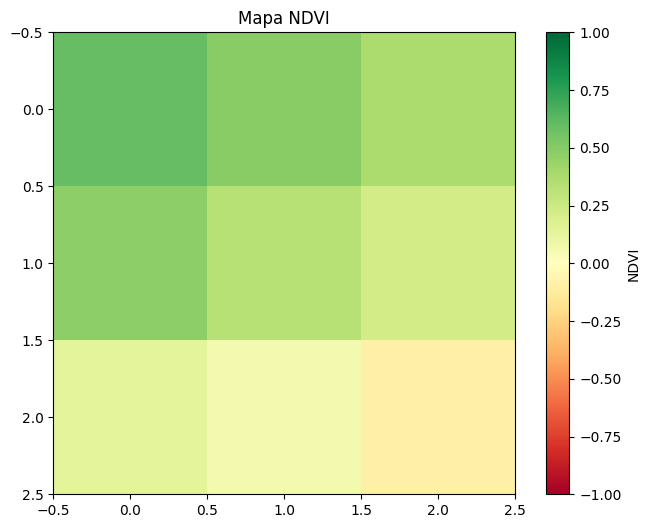

In [3]:
nir = np.array([
    [0.80, 0.72, 0.65],
    [0.70, 0.60, 0.55],
    [0.50, 0.45, 0.35]
])

red = np.array([
    [0.20, 0.25, 0.30],
    [0.25, 0.30, 0.35],
    [0.38, 0.40, 0.42]
])

ndvi_mapa = ndvi.resolve(
    nir=nir,
    red=red
)

plt.figure(
    figsize=(8, 6)
)

plt.imshow(
    ndvi_mapa,
    cmap="RdYlGn",
    vmin=-1,
    vmax=1
)

plt.colorbar(
    label="NDVI"
)

plt.title(
    "Mapa NDVI"
)

plt.show()

In [4]:
clasificacion = np.select(
    [
        ndvi_mapa < 0.1,
        ndvi_mapa < 0.2,
        ndvi_mapa < 0.5,
        ndvi_mapa < 0.7,
        ndvi_mapa >= 0.7
    ],
    [
        "Agua / suelo",
        "Vegetación muy escasa",
        "Vegetación moderada",
        "Vegetación densa",
        "Vegetación muy densa"
    ]
)

print(
    clasificacion
)

[['Vegetación densa' 'Vegetación moderada' 'Vegetación moderada']
 ['Vegetación moderada' 'Vegetación moderada' 'Vegetación moderada']
 ['Vegetación muy escasa' 'Agua / suelo' 'Agua / suelo']]


In [5]:
points = np.array([
    [0, 0],
    [1, 0],
    [2, 0],
    [0, 1],
    [1, 1],
    [2, 1],
    [0, 2],
    [1, 2],
    [2, 2]
])

nitrato = np.array([
    10,
    12,
    15,
    13,
    18,
    20,
    16,
    21,
    25
])

fosforo = np.array([
    5,
    7,
    8,
    6,
    9,
    11,
    8,
    12,
    14
])

potasio = np.array([
    20,
    24,
    28,
    22,
    30,
    34,
    27,
    35,
    40
])

grid = (
    np.linspace(0, 2, 30),
    np.linspace(0, 2, 30)
)

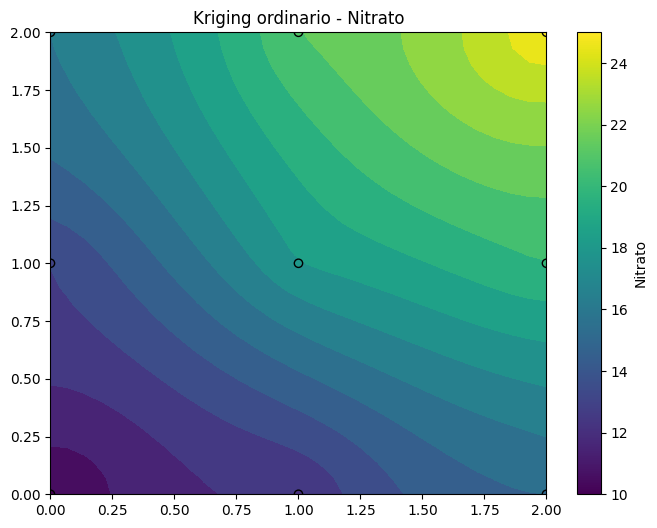

In [6]:
resultado_nitrato = kriging.resolve(
    points=points,
    values=nitrato,
    grid=grid
)

X, Y = np.meshgrid(
    grid[0],
    grid[1]
)

plt.figure(
    figsize=(8, 6)
)

plt.contourf(
    X,
    Y,
    resultado_nitrato[
        "prediction"
    ],
    levels=15
)

plt.scatter(
    points[:, 0],
    points[:, 1],
    c=nitrato,
    edgecolors="black"
)

plt.colorbar(
    label="Nitrato"
)

plt.title(
    "Kriging ordinario - Nitrato"
)

plt.show()

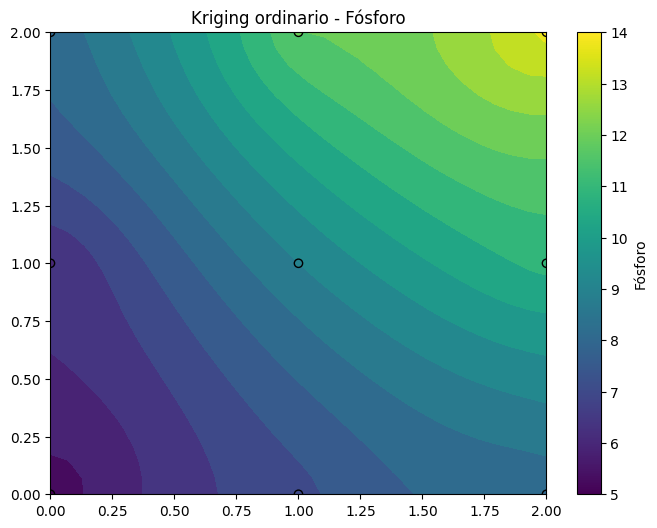

In [7]:
resultado_fosforo = kriging.resolve(
    points=points,
    values=fosforo,
    grid=grid
)

plt.figure(
    figsize=(8, 6)
)

plt.contourf(
    X,
    Y,
    resultado_fosforo[
        "prediction"
    ],
    levels=15
)

plt.scatter(
    points[:, 0],
    points[:, 1],
    c=fosforo,
    edgecolors="black"
)

plt.colorbar(
    label="Fósforo"
)

plt.title(
    "Kriging ordinario - Fósforo"
)

plt.show()

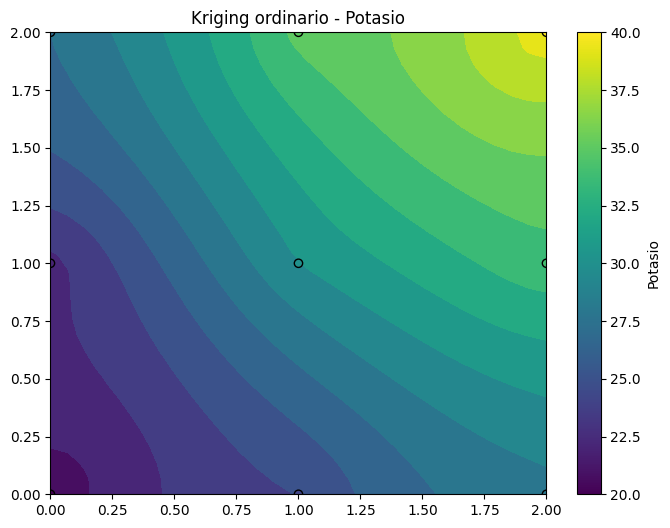

In [8]:
resultado_potasio = kriging.resolve(
    points=points,
    values=potasio,
    grid=grid
)

plt.figure(
    figsize=(8, 6)
)

plt.contourf(
    X,
    Y,
    resultado_potasio[
        "prediction"
    ],
    levels=15
)

plt.scatter(
    points[:, 0],
    points[:, 1],
    c=potasio,
    edgecolors="black"
)

plt.colorbar(
    label="Potasio"
)

plt.title(
    "Kriging ordinario - Potasio"
)

plt.show()

In [9]:
validacion = kriging.cross_validate(
    points,
    nitrato
)

print(
    "MAE:",
    validacion["MAE"]
)

print(
    "RMSE:",
    validacion["RMSE"]
)

print(
    "Observado:",
    validacion["observed"]
)

print(
    "Predicho:",
    validacion["predicted"]
)

MAE: 2.4832350474259055
RMSE: 3.0129218219145537
Observado: [10. 12. 15. 13. 18. 20. 16. 21. 25.]
Predicho: [14.44705704 14.6326429  16.35034245 14.90691068 16.5        18.77697579
 16.92716502 19.05124357 18.58678331]
